# Supervised Learning Model Evaluation Lab

Complete the exercises below to solidify your knowledge and understanding of supervised learning model evaluation.

In [1]:
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

## Regression Model Evaluation

In [2]:
column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
data = pd.read_csv('housing.csv', header=None, delimiter=r"\s+", names=column_names)
data = data.drop(columns='B')

This is the Boston housing data from the Regression lesson. As there, we drop the `B` column: it was built from the share of Black residents in each town on the assumption that this lowers house prices, and it is not a fair feature to predict prices with.

In [3]:
"""
CRIM - per capita crime rate by town
ZN - proportion of residential land zoned for lots over 25,000 sq.ft.
INDUS - proportion of non-retail business acres per town.
CHAS - Charles River dummy variable (1 if tract bounds river; 0 otherwise)
NOX - nitric oxides concentration (parts per 10 million)
RM - average number of rooms per dwelling
AGE - proportion of owner-occupied units built prior to 1940
DIS - weighted distances to five Boston employment centres
RAD - index of accessibility to radial highways
TAX - full-value property-tax rate per $10,000
PTRATIO - pupil-teacher ratio by town
LSTAT - % lower status of the population
MEDV - Median value of owner-occupied homes in $1000's"""

"\nCRIM - per capita crime rate by town\nZN - proportion of residential land zoned for lots over 25,000 sq.ft.\nINDUS - proportion of non-retail business acres per town.\nCHAS - Charles River dummy variable (1 if tract bounds river; 0 otherwise)\nNOX - nitric oxides concentration (parts per 10 million)\nRM - average number of rooms per dwelling\nAGE - proportion of owner-occupied units built prior to 1940\nDIS - weighted distances to five Boston employment centres\nRAD - index of accessibility to radial highways\nTAX - full-value property-tax rate per $10,000\nPTRATIO - pupil-teacher ratio by town\nLSTAT - % lower status of the population\nMEDV - Median value of owner-occupied homes in $1000's"

In [4]:
data

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273.0,21.0,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273.0,21.0,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273.0,21.0,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273.0,21.0,6.48,22.0


## 1. Split this data set into training (80%) and testing (20%) sets.

The `MEDV` field represents the median value of owner-occupied homes (in $1000's) and is the target variable that we will want to predict.

In [5]:
from sklearn.model_selection import train_test_split

X = data.drop(columns='MEDV')
y = data['MEDV']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(404, 12) (102, 12) (404,) (102,)


## 2. Train a `LinearRegression` model on this data set and generate predictions on both the training and the testing set.

In [6]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

y_train_pred = lr.predict(X_train)
y_test_pred = lr.predict(X_test)

pd.Series(lr.coef_, index=X.columns).round(3)

CRIM       -0.127
ZN          0.031
INDUS       0.025
CHAS        3.049
NOX       -18.183
RM          4.240
AGE        -0.004
DIS        -1.466
RAD         0.240
TAX        -0.011
PTRATIO    -0.895
LSTAT      -0.538
dtype: float64

## 3. Calculate and print R-squared for both the training and the testing set.

In [7]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print('R^2 train:', r2_score(y_train, y_train_pred))
print('R^2 test: ', r2_score(y_test, y_test_pred))

R^2 train: 0.739801993681731
R^2 test:  0.6893967884614746


## 4. Calculate and print mean squared error for both the training and the testing set.

In [8]:
print('MSE train:', mean_squared_error(y_train, y_train_pred))
print('MSE test: ', mean_squared_error(y_test, y_test_pred))

MSE train: 22.60428647941742
MSE test:  22.777708563866145


## 5. Calculate and print mean absolute error for both the training and the testing set.

In [9]:
print('MAE train:', mean_absolute_error(y_train, y_train_pred))
print('MAE test: ', mean_absolute_error(y_test, y_test_pred))

MAE train: 3.4244687759495345
MAE test:  3.111377388238188


## Classification Model Evaluation

In [10]:
from sklearn.datasets import load_iris
data = load_iris()

In [11]:
print(data.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [12]:
column_names = data.feature_names

In [13]:
df = pd.DataFrame(data['data'],columns=column_names)

In [14]:
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [15]:
target = pd.Series(data.target, name='class')

In [16]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [17]:
data['target_names']

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

## 6. Split this data set into training (80%) and testing (20%) sets.

The `class` field (`target`) represents the type of flower and is the target variable that we will want to predict.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(df, target, test_size=0.2,
                                                    stratify=target, random_state=0)
print(X_train.shape, X_test.shape)
y_test.value_counts()

(120, 4) (30, 4)


class
0    10
1    10
2    10
Name: count, dtype: int64

## 7. Train a `LogisticRegression` model on this data set and generate predictions on both the training and the testing set.

In [19]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

y_train_pred = logreg.predict(X_train)
y_test_pred = logreg.predict(X_test)

## 8. Calculate and print the accuracy score for both the training and the testing set.

In [20]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)

print(f"Accuracy train: {accuracy_score(y_train, y_train_pred):.3f}")
print(f"Accuracy test:  {accuracy_score(y_test, y_test_pred):.3f}")

Accuracy train: 0.967
Accuracy test:  1.000


## 9. Calculate and print the balanced accuracy score for both the training and the testing set.

In [21]:
print(f"Balanced accuracy train: {balanced_accuracy_score(y_train, y_train_pred):.3f}")
print(f"Balanced accuracy test:  {balanced_accuracy_score(y_test, y_test_pred):.3f}")

Balanced accuracy train: 0.967
Balanced accuracy test:  1.000


## 10. Calculate and print the precision score for both the training and the testing set.

Iris has three classes, so pass `average=` to say how to combine the per-class scores, for example `average='macro'`.

In [22]:
print(f"Precision train: {precision_score(y_train, y_train_pred, average='macro'):.3f}")
print(f"Precision test:  {precision_score(y_test, y_test_pred, average='macro'):.3f}")

Precision train: 0.967
Precision test:  1.000


## 11. Calculate and print the recall score for both the training and the testing set.

Iris has three classes, so pass `average=` to say how to combine the per-class scores, for example `average='macro'`.

In [23]:
print(f"Recall train: {recall_score(y_train, y_train_pred, average='macro'):.3f}")
print(f"Recall test:  {recall_score(y_test, y_test_pred, average='macro'):.3f}")

Recall train: 0.967
Recall test:  1.000


## 12. Calculate and print the F1 score for both the training and the testing set.

Iris has three classes, so pass `average=` to say how to combine the per-class scores, for example `average='macro'`.

In [24]:
print(f"F1 train: {f1_score(y_train, y_train_pred, average='macro'):.3f}")
print(f"F1 test:  {f1_score(y_test, y_test_pred, average='macro'):.3f}")

F1 train: 0.967
F1 test:  1.000


## 13. Generate confusion matrices for both the training and the testing set.

[[40  0  0]
 [ 0 37  3]
 [ 0  1 39]]
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


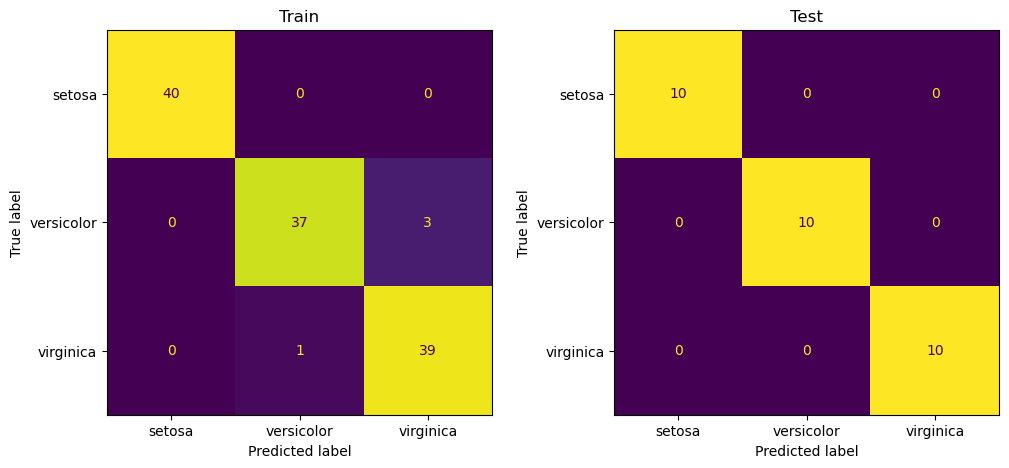

In [25]:
import matplotlib.pyplot as plt

print(confusion_matrix(y_train, y_train_pred))
print(confusion_matrix(y_test, y_test_pred))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, y_true, y_pred) in zip(axes, [('Train', y_train, y_train_pred), ('Test', y_test, y_test_pred)]):
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=data['target_names'], ax=ax, colorbar=False)
    ax.set_title(name)
plt.show()

## Bonus: For each of the data sets in this lab, try training with some of the other models you have learned about, recalculate the evaluation metrics, and compare to determine which models perform best on each data set.

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Regression: housing (X and y from exercise 1; redo the same split, since X_train/X_test now hold iris)
Xh_train, Xh_test, yh_train, yh_test = train_test_split(X, y, test_size=0.2, random_state=42)

reg_models = {
    "Linear regression": LinearRegression(),
    "Ridge, alpha=1": Ridge(alpha=1),
    "Lasso, alpha=0.1": Lasso(alpha=0.1),
    "KNN, k=5 (scaled)": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
    "Decision tree, max_depth=5": DecisionTreeRegressor(max_depth=5, random_state=0),
    "Random forest": RandomForestRegressor(random_state=0),
}

rows = []
for name, model in reg_models.items():
    model.fit(Xh_train, yh_train)
    pred_train, pred_test = model.predict(Xh_train), model.predict(Xh_test)
    rows.append({"model": name,
                 "R^2 train": r2_score(yh_train, pred_train), "R^2 test": r2_score(yh_test, pred_test),
                 "MSE test": mean_squared_error(yh_test, pred_test), "MAE test": mean_absolute_error(yh_test, pred_test)})
display(pd.DataFrame(rows).set_index("model").sort_values("R^2 test", ascending=False).round(3))

# Classification: iris
clf_models = {
    "Logistic regression": LogisticRegression(max_iter=1000),
    "KNN, k=5 (scaled)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision tree, max_depth=3": DecisionTreeClassifier(max_depth=3, random_state=0),
    "Random forest": RandomForestClassifier(random_state=0),
    "Gaussian Naive Bayes": GaussianNB(),
    "SVM, RBF kernel (scaled)": make_pipeline(StandardScaler(), SVC(kernel="rbf")),
}

rows = []
for name, model in clf_models.items():
    model.fit(X_train, y_train)
    pred_train, pred_test = model.predict(X_train), model.predict(X_test)
    rows.append({"model": name,
                 "accuracy train": accuracy_score(y_train, pred_train), "accuracy test": accuracy_score(y_test, pred_test),
                 "balanced acc test": balanced_accuracy_score(y_test, pred_test),
                 "precision test": precision_score(y_test, pred_test, average='macro'),
                 "recall test": recall_score(y_test, pred_test, average='macro'),
                 "F1 test": f1_score(y_test, pred_test, average='macro')})
pd.DataFrame(rows).set_index("model").sort_values("F1 test", ascending=False).round(3)

,R^2 train,R^2 test,MSE test,MAE test
model,,,,
"Decision tree, max_depth=5",0.918,0.879,8.846,2.367
Random forest,0.976,0.879,8.846,2.070
"KNN, k=5 (scaled)",0.842,0.719,20.614,2.625
Linear regression,0.740,0.689,22.778,3.111
"Ridge, alpha=1",0.737,0.686,23.007,3.059
"Lasso, alpha=0.1",0.726,0.676,23.730,3.094


,accuracy train,accuracy test,balanced acc test,precision test,recall test,F1 test
model,,,,,,
Logistic regression,0.967,1.000,1.000,1.000,1.000,1.000
"SVM, RBF kernel (scaled)",0.967,1.000,1.000,1.000,1.000,1.000
"KNN, k=5 (scaled)",0.967,0.967,0.967,0.970,0.967,0.967
Gaussian Naive Bayes,0.950,0.967,0.967,0.970,0.967,0.967
"Decision tree, max_depth=3",0.967,0.933,0.933,0.944,0.933,0.933
Random forest,1.000,0.933,0.933,0.944,0.933,0.933
